# Axis 2 — Tools

**Owner: Member 2 · Branch: `axis-2` · Status: starting notebook, not a completed investigation.**

**Question:** Which coding assistants have respondents used and which do they want to try?

**Use for the sponsor:** Help select tools to examine in a pilot without confusing popularity with quality.

The proposed sponsor is a DINUM team planning an AI coding-assistant pilot. These French survey respondents are not a sample of DINUM staff. Use the shared population and denominator rules before changing them.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the project root or its notebooks folder.")
sys.path.insert(0, str(ROOT))
from src.data import ensure_data, load_responses, load_schema
from src.population import prepare_population

ensure_data()
population = prepare_population(load_responses())
schema = load_schema()
print("2026 · France · coding as primary job · eligible respondents:", len(population))

2026 · France · coding as primary job · eligible respondents: 628


## 1. Check the fields and the answering population

In [2]:
fields = ['AICodeAgentHaveWorkedWith', 'AICodeAgentWantToUseNext6Months', 'LLMHaveWorkedWith']
display(schema.loc[schema["column"].isin(fields), ["column", "question", "sub", "transformation"]])
display(pd.DataFrame({"answered": population[fields].notna().sum(),
                      "unanswered": population[fields].isna().sum()}))

,column,question,sub,transformation
72,LLMHaveWorkedWith,Which LLM model vendors for AI tools have you ...,Worked with in past year,"Distinct selections, semicolon-separated"
140,AICodeAgentHaveWorkedWith,Have you used any of the following coding agen...,Used in the past year,"Distinct selections, semicolon-separated"
141,AICodeAgentWantToUseNext6Months,Have you used any of the following coding agen...,Want to use in the next 6 months,"Distinct selections, semicolon-separated"


,answered,unanswered
AICodeAgentHaveWorkedWith,334,294
AICodeAgentWantToUseNext6Months,201,427
LLMHaveWorkedWith,332,296


## 2. A first descriptive view
This is a starting calculation. Record a factual observation and a separate question after inspecting it.

,answer,respondents,share_pct
0,Claude Code,222,66.467066
1,GitHub Copilot,192,57.485030
2,Cursor,75,22.455090
3,OpenAI Codex,59,17.664671
4,Open Code,43,12.874251
5,JetBrains AI,41,12.275449
6,Mistral Vibe,39,11.676647
7,Google Antigravity,37,11.077844
8,Gemini Code Assist,28,8.383234
9,Continue,19,5.688623


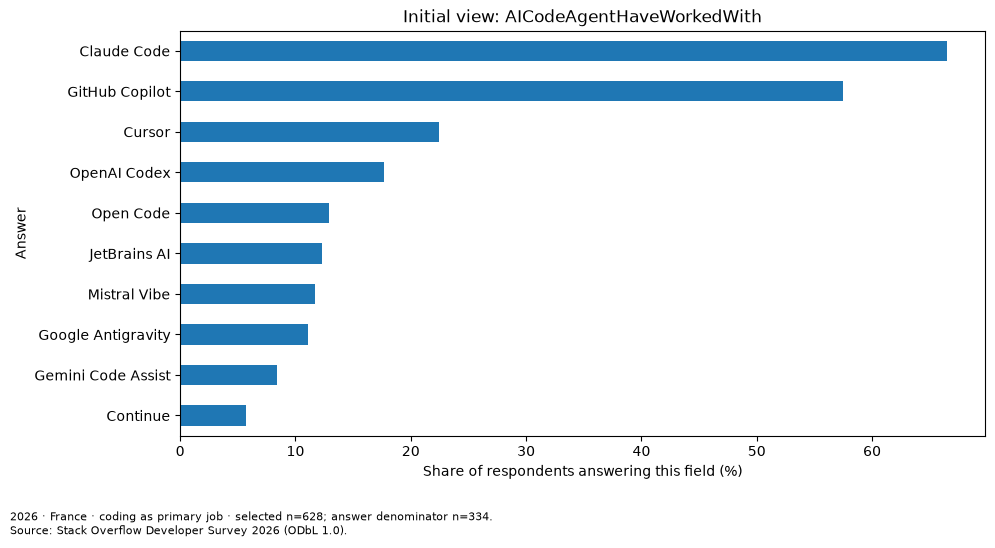

In [3]:
from src.analysis.axis_2 import summarise

column = 'AICodeAgentHaveWorkedWith'
table, answered_n = summarise(population, column)
display(table.head(10))
ax = table.head(10).iloc[::-1].plot.barh(x="answer", y="share_pct", legend=False, figsize=(10, 5))
ax.set(title="Initial view: " + column, xlabel="Share of respondents answering this field (%)", ylabel="Answer")
plt.figtext(.01, -.08, f"2026 · France · coding as primary job · selected n={len(population)}; answer denominator n={answered_n}.\nSource: Stack Overflow Developer Survey 2026 (ODbL 1.0).", fontsize=8)
plt.tight_layout()
plt.show()

## 3. Work still to do — Member 2

1. Explore several useful views and write separate **I notice** / **I wonder** entries.
2. Formulate a testable hypothesis arising from those observations.
3. Examine combinations or a profile subgroup. Keep used and wanted populations separate, inspect non-response and explain why these columns do not establish adoption growth.
4. Explain what the evidence supports, what remains uncertain and what cannot be concluded.
5. Add one useful interaction and one clear view to `views/axis_2.py`, with calculations in `src/analysis/axis_2.py`.
6. Check the shared app and explain the code. Ask the assigned reviewer to read the PR.

Write your own analysis below this plan. The starter calculation is not a finished individual submission.